# Aula 10 — Testando a biblioteca

Apos finalizar todos as 10 aulas, foi criado um biblioteca com toda as funções.

Esta aula usa a biblioteca `qbasic` (instale com `pip install Q-BASIC`). Desde a versão 0.1 os nomes não têm acento: `destruicao`, `criacao`, `identidade`, `fock`, `resolver_schrodinger`... Os nomes antigos (`destruiçao`, `edo.solve`) ainda funcionam, mas mostram um aviso.

Convenção: o átomo tem estado fundamental $|0\rangle$ e excitado $|1\rangle$, e `destruicao(2)` é o operador $\sigma_- = |0\rangle\langle 1|$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import qbasic as qb

In [2]:
wc = 1.0 * 2 * np.pi  # frequência da cavidade
wa = 1.0 * 2 * np.pi  # frequência do átomo
g = 0.05 * 2 * np.pi  # acoplamento átomo-cavidade

N = 2  # níveis de Fock da cavidade

# Estado inicial: cavidade no vácuo e átomo excitado (|1>)
psi0 = qb.tensor(qb.fock(N, 0), qb.ket("1"))

# Operadores no espaço cavidade ⊗ átomo
a = qb.tensor(qb.destruicao(N), qb.identidade(2))  # destrói um fóton
sm = qb.tensor(qb.identidade(N), qb.destruicao(2))  # sigma-menos do átomo: |1> -> |0>

# Hamiltoniano de Jaynes-Cummings
H_acoplamento = g * (a.dag() * sm + a * sm.dag())
H = wc * a.dag() * a + wa * sm.dag() * sm + H_acoplamento

tempo = np.linspace(0, 10, 100)  # instantes de tempo

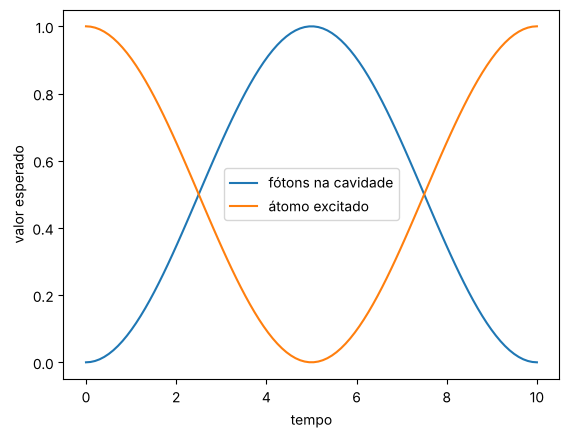

In [3]:
# Resolve a equação de Schrödinger e calcula os valores esperados
n_fotons = a.dag() * a  # número de fótons na cavidade
p_excitado = sm.dag() * sm  # população do estado excitado do átomo

resultado = qb.resolver_schrodinger(H, psi0, tempo, observaveis=[n_fotons, p_excitado])

plt.plot(tempo, resultado.valores_esperados[0], label="fótons na cavidade")
plt.plot(tempo, resultado.valores_esperados[1], label="átomo excitado")
plt.xlabel("tempo")
plt.ylabel("valor esperado")
plt.legend()
plt.show()